# Table of Contents
- [5.0 Introduction: physics is written in differential equations](#intro)
- [5.1 Direction fields and isoclines](#isoclines)
- [5.2 Euler's method](#euler)
- [5.3 Improved Euler (Heun) and the Taylor series method](#heun)
- [5.4 The Runge-Kutta method (RK4)](#rk4)
- [5.5 Higher-order equations and systems](#systems)
- [5.6 Energy conservation and symplectic integrators](#symplectic)
- [5.7 Adaptive step sizes and `scipy.integrate.solve_ivp`](#adaptive)
- [5.8 Stiff equations](#stiff)
- [5.9 Boundary value problems: the shooting method](#shooting)
- [Problems](#problems)

# 5.0 Introduction: physics is written in differential equations <a class="anchor" id="intro"></a>
Newton's second law, Maxwell's equations, the Schrödinger equation, radioactive decay, population dynamics, chemical kinetics... almost every law of physics is a differential equation. Sadly, most of the ones you meet in research cannot be solved with pen and paper.

In this chapter we solve the **initial value problem** (IVP)

$$\frac{dy}{dt} = f(t, y), \qquad y(t_0) = y_0.$$

The idea of every method is to march forward in small steps $h$: $t_{n+1}=t_n+h$, computing $y_{n+1}\approx y(t_{n+1})$ from what we already know. Note that $y$ can be a **vector** - that's how we'll handle systems and higher-order equations.

In [1]:
# BLOCK 5.0.1
import numpy as np
import matplotlib.pyplot as plt

# 5.1 Direction fields and isoclines <a class="anchor" id="isoclines"></a>
Before solving anything, we can *see* the solution. The ODE tells us the gradient $dy/dt$ at every point in the $(t,y)$ plane. Drawing a short arrow with that gradient at every point of a grid gives a **direction field**; solution curves must be tangent to the arrows everywhere.

An **isocline** is a curve along which the gradient is constant, $f(t,y)=c$. Drawing a few isoclines was the classic hand-method for sketching solutions.

Let's look at $\dfrac{dy}{dt} = t - y$, whose isoclines are the straight lines $y = t - c$.

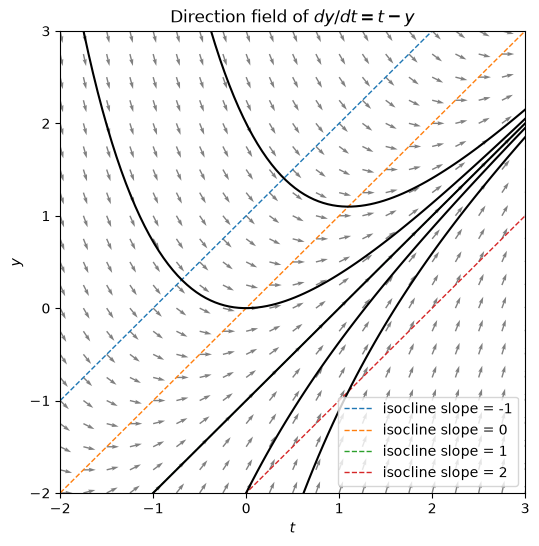

In [2]:
# BLOCK 5.1.1
def f(t, y):
    return t - y

T, Y = np.meshgrid(np.linspace(-2, 3, 21), np.linspace(-2, 3, 21))
S = f(T, Y)
L = np.sqrt(1 + S**2)                       # normalise arrows to the same length
plt.figure(figsize=(6, 6))
plt.quiver(T, Y, 1/L, S/L, angles='xy', color='grey', width=0.003)

t = np.linspace(-2, 3, 100)
for c in [-1, 0, 1, 2]:
    plt.plot(t, t - c, '--', lw=1, label=f'isocline slope = {c}')
# exact solutions y = t - 1 + C e^{-t}
for C in [-3, -1, 0, 1, 3]:
    plt.plot(t, t - 1 + C*np.exp(-t), 'k', lw=1.5)
plt.xlim(-2, 3); plt.ylim(-2, 3); plt.xlabel('$t$'); plt.ylabel('$y$')
plt.title(r'Direction field of $dy/dt = t - y$'); plt.legend(loc='lower right'); plt.show()

Notice that the isocline with slope 1, $y=t-1$, is itself a solution: every other solution is attracted towards it.

# 5.2 Euler's method <a class="anchor" id="euler"></a>
The simplest idea: follow the arrow. Use the forward difference from Chapter 4,

$$\frac{y_{n+1}-y_n}{h}\approx f(t_n, y_n) \quad\Longrightarrow\quad \boxed{y_{n+1} = y_n + h\,f(t_n, y_n)}.$$

Each step makes a local error $\mathcal{O}(h^2)$, and we take $\sim1/h$ steps, so the **global** error is $\mathcal{O}(h)$ - first order.

We'll write all our solvers with the same signature, `solver(f, y0, t)`, so we can swap them freely. `y0` can be a number or a numpy array.

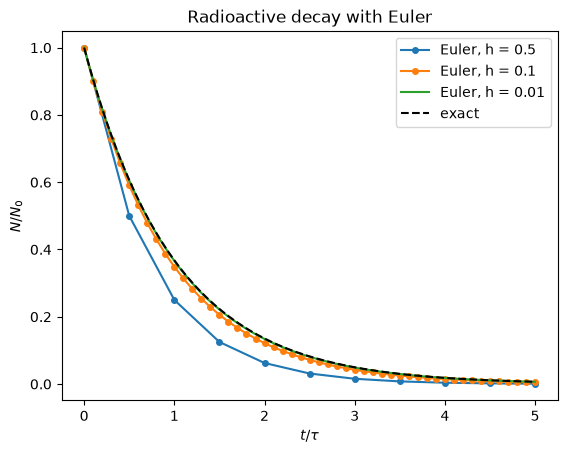

In [3]:
# BLOCK 5.2.1
def euler(f, y0, t):
    y = np.zeros((len(t), np.size(y0)))
    y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        y[n+1] = y[n] + h*f(t[n], y[n])
    return y.squeeze()

# Radioactive decay dN/dt = -N/tau, exact answer N0 exp(-t/tau)
tau = 1.0
decay = lambda t, N: -N/tau
for h in [0.5, 0.1, 0.01]:
    t = np.arange(0, 5 + h/2, h)
    N = euler(decay, 1.0, t)
    plt.plot(t, N, 'o-' if h > 0.05 else '-', ms=4, label=f'Euler, h = {h}')
t = np.linspace(0, 5, 200)
plt.plot(t, np.exp(-t/tau), 'k--', label='exact')
plt.xlabel('$t/\\tau$'); plt.ylabel('$N/N_0$'); plt.legend(); plt.title('Radioactive decay with Euler')
plt.show()

# 5.3 Improved Euler (Heun) and the Taylor series method <a class="anchor" id="heun"></a>
Euler uses the gradient at the **start** of the step for the whole step. Better: take a trial Euler step, evaluate the gradient at the **end** too, and use the average (like the trapezium rule!):

$$k_1 = f(t_n, y_n),\qquad k_2 = f(t_n + h,\; y_n + h k_1),\qquad y_{n+1} = y_n + \frac{h}{2}(k_1+k_2).$$

This is **second order**. It is also our first *predictor-corrector* method.

**The Taylor series method.** An alternative route to higher order is to keep more terms of the Taylor series,
$y_{n+1} = y_n + h y'_n + \tfrac{h^2}{2} y''_n + \dots$, where $y'' = \frac{d}{dt}f(t,y) = f_t + f_y f$ is found by differentiating the ODE by hand. It works, but requires messy derivatives of $f$ for every new problem. Runge-Kutta methods get the same accuracy using only evaluations of $f$.

In [4]:
# BLOCK 5.3.1
def heun(f, y0, t):
    y = np.zeros((len(t), np.size(y0)))
    y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        k1 = f(t[n], y[n])
        k2 = f(t[n] + h, y[n] + h*k1)
        y[n+1] = y[n] + 0.5*h*(k1 + k2)
    return y.squeeze()

# Taylor series method (2nd order) for dy/dt = t - y:  y'' = 1 - y' = 1 - (t - y)
def taylor2_example(y0, t):
    y = np.zeros(len(t)); y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        d1 = t[n] - y[n]
        d2 = 1 - d1
        y[n+1] = y[n] + h*d1 + 0.5*h**2*d2
    return y

t = np.linspace(0, 2, 11)
exact = t - 1 + 2*np.exp(-t)          # solution with y(0) = 1
print(f'error at t = 2:  Euler {abs(euler(f, 1.0, t)[-1] - exact[-1]):.2e}, '
      f'Heun {abs(heun(f, 1.0, t)[-1] - exact[-1]):.2e}, '
      f'Taylor-2 {abs(taylor2_example(1.0, t)[-1] - exact[-1]):.2e}')

error at t = 2:  Euler 5.59e-02, Heun 4.23e-03, Taylor-2 4.23e-03


Heun is about 13 times more accurate than Euler here for the same step size. (For this *linear* ODE, Heun and the 2nd-order Taylor method happen to be algebraically identical - expand $k_2$ and see!)

# 5.4 The Runge-Kutta method (RK4) <a class="anchor" id="rk4"></a>
The classic fourth-order Runge-Kutta method samples the gradient four times per step - at the start, twice at the middle, and at the end - and takes a weighted average (with Simpson-like weights $1,2,2,1$):

$$\begin{aligned}
k_1 &= f(t_n,\; y_n) \\
k_2 &= f(t_n + \tfrac{h}{2},\; y_n + \tfrac{h}{2}k_1) \\
k_3 &= f(t_n + \tfrac{h}{2},\; y_n + \tfrac{h}{2}k_2) \\
k_4 &= f(t_n + h,\; y_n + h k_3) \\
y_{n+1} &= y_n + \tfrac{h}{6}(k_1 + 2k_2 + 2k_3 + k_4)
\end{aligned}$$

RK4 has been the default "just works" ODE solver for a century. Learn it by heart!

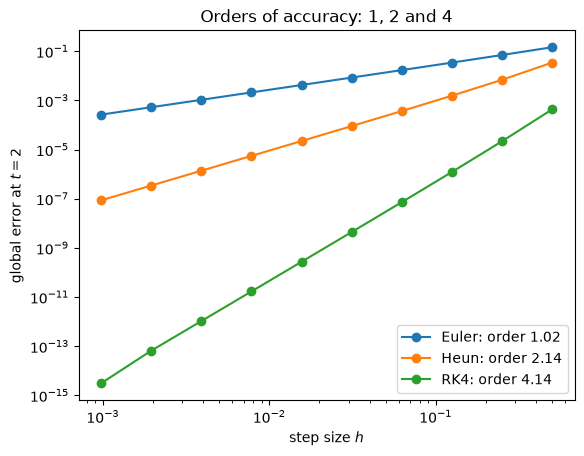

In [5]:
# BLOCK 5.4.1
def rk4(f, y0, t):
    y = np.zeros((len(t), np.size(y0)))
    y[0] = y0
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        k1 = f(t[n], y[n])
        k2 = f(t[n] + h/2, y[n] + h/2*k1)
        k3 = f(t[n] + h/2, y[n] + h/2*k2)
        k4 = f(t[n] + h, y[n] + h*k3)
        y[n+1] = y[n] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return y.squeeze()

# Convergence study on dy/dt = t - y, y(0) = 1
Ns = 2**np.arange(2, 12)
for name, solver in [('Euler', euler), ('Heun', heun), ('RK4', rk4)]:
    errs = []
    for N in Ns:
        t = np.linspace(0, 2, N + 1)
        errs.append(abs(solver(f, 1.0, t)[-1] - (1 + np.exp(-2)*2)))
    errs = np.array(errs)
    p = -np.polyfit(np.log(2/Ns[:5]), np.log(errs[:5]), 1)[0]
    plt.loglog(2/Ns, errs, 'o-', label=f'{name}: order {-p:.2f}')
plt.xlabel('step size $h$'); plt.ylabel('global error at $t=2$'); plt.legend()
plt.title('Orders of accuracy: 1, 2 and 4'); plt.show()

# 5.5 Higher-order equations and systems <a class="anchor" id="systems"></a>
Every solver above only knows about *first-order* equations. The trick to solve a second-order equation such as Newton's law

$$\ddot x = F(x, \dot x, t)/m$$

is to introduce the velocity as a new variable and write a **first-order system** for the state vector $\mathbf{y} = (x, v)$:

$$\frac{d}{dt}\begin{pmatrix}x\\ v\end{pmatrix} = \begin{pmatrix} v \\ F(x,v,t)/m\end{pmatrix}.$$

Because our solvers already work with numpy arrays, nothing else needs to change. An $n$-th order ODE becomes $n$ first-order ones.

**Example: the damped, driven oscillator** $\;\ddot x + 2\gamma\dot x + \omega_0^2 x = F_0\cos(\omega t)$.

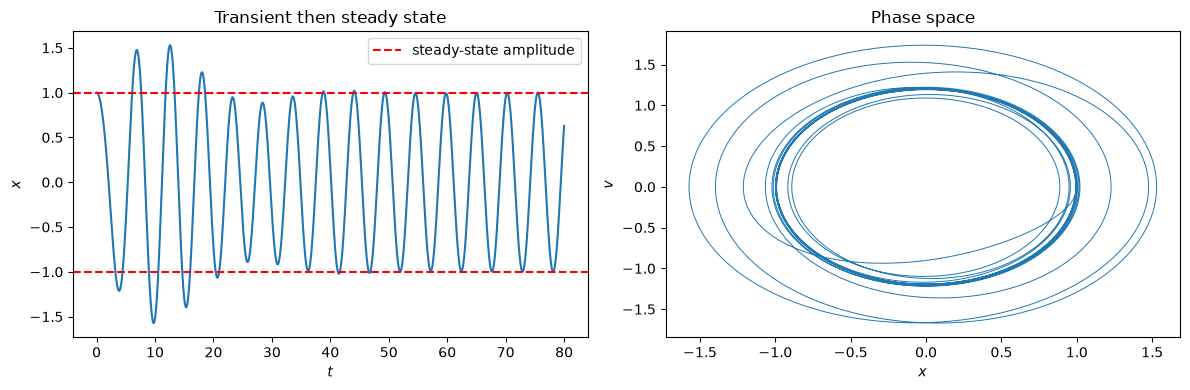

In [6]:
# BLOCK 5.5.1
gamma, w0, F0, w = 0.1, 1.0, 0.5, 1.2

def oscillator(t, y):
    x, v = y
    return np.array([v, -2*gamma*v - w0**2*x + F0*np.cos(w*t)])

t = np.linspace(0, 80, 4001)
sol = rk4(oscillator, np.array([1.0, 0.0]), t)

# steady-state amplitude from the textbook formula
A = F0/np.sqrt((w0**2 - w**2)**2 + (2*gamma*w)**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(t, sol[:, 0]); ax1.axhline(A, ls='--', c='r'); ax1.axhline(-A, ls='--', c='r', label='steady-state amplitude')
ax1.set_xlabel('$t$'); ax1.set_ylabel('$x$'); ax1.legend(); ax1.set_title('Transient then steady state')
ax2.plot(sol[:, 0], sol[:, 1], lw=0.7); ax2.set_xlabel('$x$'); ax2.set_ylabel('$v$'); ax2.set_title('Phase space')
plt.tight_layout(); plt.show()

# 5.6 Energy conservation and symplectic integrators <a class="anchor" id="symplectic"></a>
Here's a subtle problem. Solve the undamped oscillator $\ddot x=-x$ for a long time and watch the energy $E=\tfrac12(v^2+x^2)$, which should be exactly conserved.

In [7]:
# BLOCK 5.6.1
sho = lambda t, y: np.array([y[1], -y[0]])
t = np.linspace(0, 200, 2001)          # h = 0.1, ~30 orbits
energy = lambda s: 0.5*(s[:, 0]**2 + s[:, 1]**2)

E_euler = energy(euler(sho, np.array([1.0, 0.0]), t))
E_rk4 = energy(rk4(sho, np.array([1.0, 0.0]), t))
print(f'Euler: E grew from 0.5 to {E_euler[-1]:.3e}')
print(f'RK4  : E drifted from 0.5 to {E_rk4[-1]:.8f}')

Euler: E grew from 0.5 to 2.196e+08
RK4  : E drifted from 0.5 to 0.49998613


Euler is catastrophic - the orbit spirals outward because each step adds energy. RK4 is far better, but its energy *still* drifts steadily downward. For a planetary orbit over a billion years that's a disaster.

**Symplectic integrators** respect the geometric structure of Hamiltonian mechanics (they conserve phase-space area). They don't conserve energy exactly, but the energy error *oscillates and stays bounded forever* rather than drifting. The most famous is **velocity Verlet** (a.k.a. *leapfrog*), for $\ddot x = a(x)$:

$$\begin{aligned}
v_{n+1/2} &= v_n + \tfrac{h}{2}a(x_n)\\
x_{n+1} &= x_n + h\,v_{n+1/2}\\
v_{n+1} &= v_{n+1/2} + \tfrac{h}{2}a(x_{n+1})
\end{aligned}$$

It's only second order, and needs just **one** force evaluation per step - yet it is the integrator of choice in molecular dynamics, N-body astrophysics and particle accelerator design.

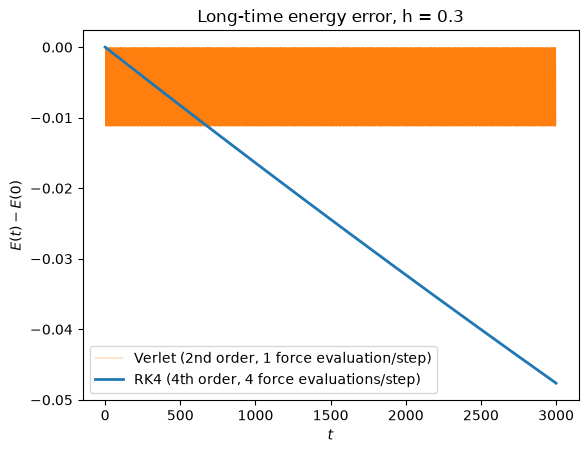

In [8]:
# BLOCK 5.6.2
def velocity_verlet(accel, x0, v0, t):
    """Integrate x'' = accel(x). x0, v0 may be arrays (e.g. 2D or 3D positions)."""
    x = np.zeros((len(t),) + np.shape(x0)); v = np.zeros_like(x)
    x[0], v[0] = x0, v0
    a = accel(x0)
    for n in range(len(t) - 1):
        h = t[n+1] - t[n]
        v_half = v[n] + 0.5*h*a
        x[n+1] = x[n] + h*v_half
        a = accel(x[n+1])
        v[n+1] = v_half + 0.5*h*a
    return x, v

t_long = np.linspace(0, 3000, 10001)     # ~480 orbits with a big step, h = 0.3
x, v = velocity_verlet(lambda x: -x, 1.0, 0.0, t_long)
E_verlet = 0.5*(x**2 + v**2)
E_rk4_long = energy(rk4(sho, np.array([1.0, 0.0]), t_long))

plt.plot(t_long, E_verlet - 0.5, lw=0.3, color='tab:orange', label='Verlet (2nd order, 1 force evaluation/step)')
plt.plot(t_long, E_rk4_long - 0.5, lw=2, color='tab:blue', label='RK4 (4th order, 4 force evaluations/step)')
plt.xlabel('$t$'); plt.ylabel('$E(t) - E(0)$'); plt.legend(loc='lower left')
plt.title('Long-time energy error, h = 0.3'); plt.show()

Verlet's energy error wobbles (the orange band) but never grows; RK4's error is smaller at first but marches steadily downwards and eventually loses. For long simulations of conservative systems, structure beats order.

# 5.7 Adaptive step sizes and `scipy.integrate.solve_ivp` <a class="anchor" id="adaptive"></a>
A comet on an eccentric orbit moves slowly far from the Sun and very fast close to it. A fixed $h$ small enough for perihelion is hugely wasteful at aphelion. **Adaptive** methods estimate the error of every step and change $h$ to keep it below a tolerance.

The simplest error estimate is **step doubling**: take one step of size $h$ and two of size $h/2$ and compare. Modern solvers use *embedded* Runge-Kutta pairs instead (e.g. Dormand-Prince RK45), which produce a 4th and 5th order answer from the same six function evaluations; their difference is the error estimate.

Then if the error estimate is $\Delta$ and the tolerance is $\delta$, the next step size is $h_{\text{new}} = 0.9\,h\,(\delta/\Delta)^{1/5}$.

Here's a minimal adaptive RK4 with step doubling:

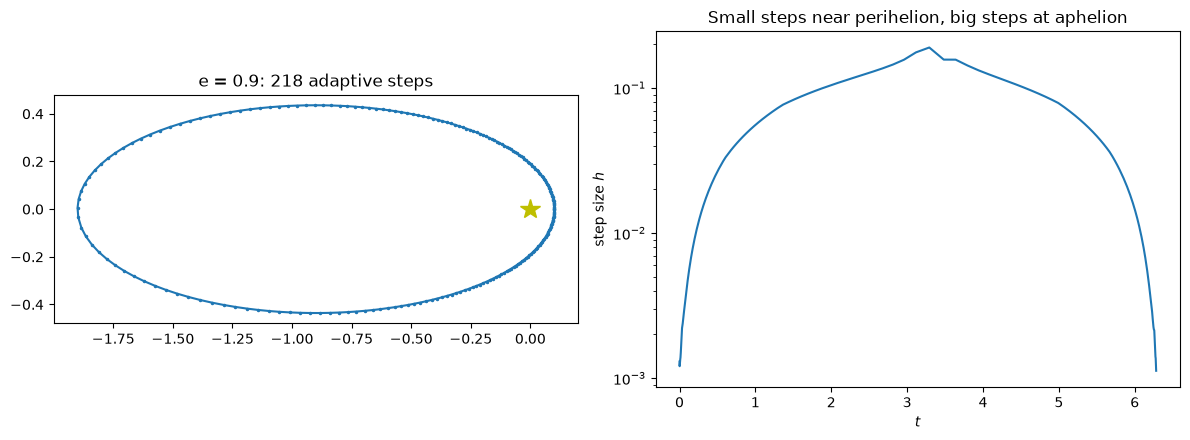

closure error after one orbit: 5.512160394402761e-06


In [9]:
# BLOCK 5.7.1
def rk4_step(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + h/2, y + h/2*k1)
    k3 = f(t + h/2, y + h/2*k2)
    k4 = f(t + h, y + h*k3)
    return y + h/6*(k1 + 2*k2 + 2*k3 + k4)

def rk4_adaptive(f, y0, t0, t_end, h=0.01, tol=1e-8):
    ts, ys = [t0], [np.array(y0, float)]
    t, y = t0, np.array(y0, float)
    while t < t_end:
        h = min(h, t_end - t)
        big = rk4_step(f, t, y, h)
        half = rk4_step(f, t + h/2, rk4_step(f, t, y, h/2), h/2)
        err = np.max(np.abs(big - half)) / 15        # Richardson: error of 'half'
        if err <= tol:                                # accept the step
            t, y = t + h, half + (half - big)/15      # (and extrapolate for free)
            ts.append(t); ys.append(y)
        h *= min(4, 0.9*(tol/max(err, 1e-300))**0.2)  # grow or shrink h
    return np.array(ts), np.array(ys)

# A comet on an eccentric Kepler orbit (units: GM = 1)
def kepler(t, s):
    x, y, vx, vy = s
    r3 = (x*x + y*y)**1.5
    return np.array([vx, vy, -x/r3, -y/r3])

e = 0.9                                            # eccentricity
s0 = [1 - e, 0, 0, np.sqrt((1 + e)/(1 - e))]       # start at perihelion
T = 2*np.pi                                        # period for semi-major axis a = 1
ts, ys = rk4_adaptive(kepler, s0, 0, T, tol=1e-9)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ys[:, 0], ys[:, 1], '.-', ms=3); ax1.plot(0, 0, 'y*', ms=15)
ax1.set_aspect('equal'); ax1.set_title(f'e = {e}: {len(ts)} adaptive steps')
ax2.semilogy(ts[:-1], np.diff(ts)); ax2.set_xlabel('$t$'); ax2.set_ylabel('step size $h$')
ax2.set_title('Small steps near perihelion, big steps at aphelion')
plt.tight_layout(); plt.show()
print('closure error after one orbit:', np.linalg.norm(ys[-1] - s0))

In practice, use `scipy.integrate.solve_ivp`. Its interface is the same `f(t, y)` we've been using. Always set `rtol` and `atol` - the defaults ($10^{-3}$, $10^{-6}$) are loose!

In [10]:
# BLOCK 5.7.2
from scipy.integrate import solve_ivp

sol = solve_ivp(kepler, (0, T), s0, method='DOP853', rtol=1e-10, atol=1e-12, dense_output=True)
print(sol.message, f'| {sol.t.size} steps, {sol.nfev} function evaluations')
print('closure error after one orbit:', np.linalg.norm(sol.y[:, -1] - s0))

# dense_output lets you evaluate the solution at any time, e.g. half a period:
print('position at t = T/2 (should be aphelion, x = -1.9):', sol.sol(T/2)[:2])

The solver successfully reached the end of the integration interval. | 83 steps, 1616 function evaluations
closure error after one orbit: 2.0497826848973207e-07
position at t = T/2 (should be aphelion, x = -1.9): [-1.90000000e+00  2.04423697e-10]


# 5.8 Stiff equations <a class="anchor" id="stiff"></a>
A system is **stiff** when it contains processes on wildly different time-scales - e.g. a fast chemical reaction feeding a slow one, or a circuit with a tiny and a huge time-constant. Explicit methods must use a step size small enough to resolve the *fastest* time-scale even after it has died away, otherwise they blow up.

Consider $y' = -1000(y - \cos t)$. The solution rapidly locks onto $y\approx\cos t$ and then varies slowly, yet explicit Euler is unstable unless $h < 2/1000$.

**Implicit (backward) Euler** evaluates $f$ at the *new* point, $y_{n+1} = y_n + h f(t_{n+1}, y_{n+1})$. This requires solving an equation each step (here it's linear, so we can rearrange by hand), but it is stable for any $h$.

In [11]:
# BLOCK 5.8.1
k = 1000
stiff = lambda t, y: -k*(y - np.cos(t))

t = np.linspace(0, 2, 41)       # h = 0.05, way above the 2/k = 0.002 stability limit
y_explicit = euler(stiff, 0.0, t)

y_implicit = np.zeros_like(t)   # backward Euler, rearranged: y_{n+1} = (y_n + h k cos t_{n+1}) / (1 + h k)
for n in range(len(t) - 1):
    h = t[n+1] - t[n]
    y_implicit[n+1] = (y_implicit[n] + h*k*np.cos(t[n+1])) / (1 + h*k)

print('explicit Euler at t=2:', y_explicit[-1])
print('implicit Euler at t=2:', y_implicit[-1], '  cos(2) =', np.cos(2))

for method in ['RK45', 'Radau']:
    s = solve_ivp(stiff, (0, 2), [0.0], method=method, rtol=1e-6)
    print(f'solve_ivp {method:<6}: {s.nfev:>5} function evaluations')

explicit Euler at t=2: -4.0537188311307594e+67
implicit Euler at t=2: -0.4152271472774607   cos(2) = -0.4161468365471424
solve_ivp RK45  :  4016 function evaluations
solve_ivp Radau :   327 function evaluations


The implicit `Radau` method needs far fewer evaluations than `RK45`. If `solve_ivp` seems to take forever, try `method='Radau'` or `'LSODA'`.

# 5.9 Boundary value problems: the shooting method <a class="anchor" id="shooting"></a>
Sometimes conditions are given at **both ends**: a projectile that must hit a target, a string fixed at both ends, or a quantum particle in a box with $\psi(0)=\psi(L)=0$. This is a **boundary value problem** (BVP).

The shooting method turns a BVP into a root-finding problem (Chapter 3!):
1. Guess the missing initial condition (e.g. the initial slope $s$).
2. Integrate as an IVP to the far end.
3. Measure the miss distance $F(s) = y(L; s) - y_{\text{target}}$.
4. Find the root of $F(s)$ with the secant method or `brentq`.

**Example:** a cannonball with quadratic air resistance must be fired at speed $v_0 = 100$ m/s to land $R=350$ m away. At what angle?

Hit the target at theta = 18.0104 deg or 61.5322 deg


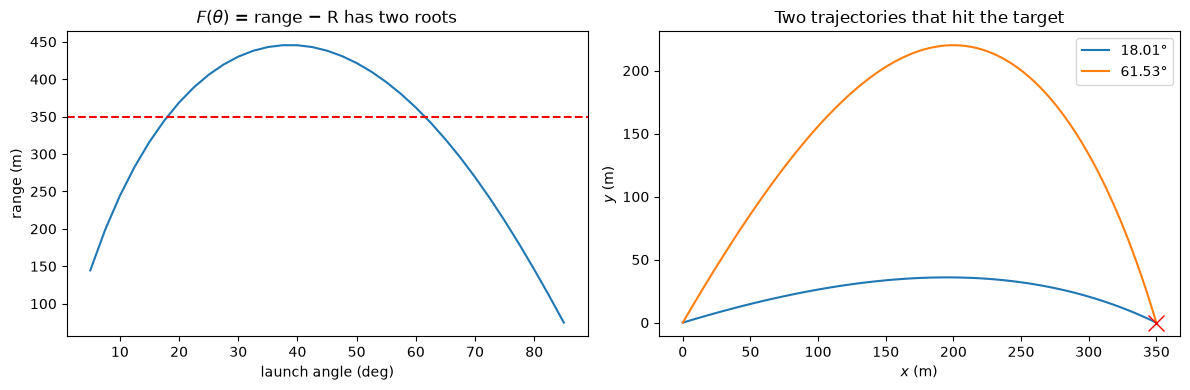

In [12]:
# BLOCK 5.9.1
from scipy.optimize import brentq

g, c = 9.81, 0.002          # c = drag coefficient / mass (1/m)
v0, R = 100.0, 350.0

def projectile(t, s):
    x, y, vx, vy = s
    v = np.hypot(vx, vy)
    return [vx, vy, -c*v*vx, -g - c*v*vy]

def hit_ground(t, s):        # an 'event' - solve_ivp stops when this crosses zero
    return s[1]
hit_ground.terminal, hit_ground.direction = True, -1

def landing_x(theta_deg):
    th = np.radians(theta_deg)
    s = solve_ivp(projectile, (0, 100), [0, 0, v0*np.cos(th), v0*np.sin(th)],
                  events=hit_ground, rtol=1e-9, max_step=0.05)
    return s.y_events[0][0][0], s

miss = lambda theta: landing_x(theta)[0] - R
thetas = np.linspace(5, 85, 33)
ranges = [landing_x(th)[0] for th in thetas]
low = brentq(miss, 5, 35)        # two solutions: a low and a high trajectory
high = brentq(miss, 40, 85)
print(f'Hit the target at theta = {low:.4f} deg or {high:.4f} deg')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(thetas, ranges); ax1.axhline(R, ls='--', c='r'); ax1.set_xlabel('launch angle (deg)'); ax1.set_ylabel('range (m)')
ax1.set_title('$F(\\theta)$ = range $-$ R has two roots')
for th in [low, high]:
    s = landing_x(th)[1]
    ax2.plot(s.y[0], s.y[1], label=f'{th:.2f}°')
ax2.plot(R, 0, 'rx', ms=12); ax2.set_xlabel('$x$ (m)'); ax2.set_ylabel('$y$ (m)'); ax2.legend()
ax2.set_title('Two trajectories that hit the target')
plt.tight_layout(); plt.show()

Notice that with air resistance the maximum range is at roughly $40^\circ$, not the $45^\circ$ you learned for the drag-free case.

We'll use the shooting method again in the Quantum Mechanics application notebook to find energy eigenvalues, where the "missing" parameter is the energy $E$ itself. (`scipy.integrate.solve_bvp` is a robust library alternative.)

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - RC circuit
A capacitor charges through a resistor: $\dot Q = (V_0 - Q/C)/R$. Solve with Euler and RK4 for a few step sizes and compare with $Q=CV_0(1-e^{-t/RC})$. What is the largest step for which Euler doesn't oscillate?

### Exercise 2 - The Lotka-Volterra equations
Solve the predator-prey model $\dot x = \alpha x - \beta xy$, $\dot y = \delta xy - \gamma y$ with $\alpha=1.1,\beta=0.4,\delta=0.1,\gamma=0.4$, $x_0=10,y_0=10$. Plot both populations against time and the phase-space orbit. The quantity $V=\delta x-\gamma\ln x+\beta y-\alpha\ln y$ is conserved - how well does each method conserve it?

### Exercise 3 - Write RK45 yourself
Look up the Butcher tableau of the Dormand-Prince method and implement an adaptive solver with it. Compare the number of function evaluations with `rk4_adaptive` for the $e=0.9$ Kepler orbit.

### Exercise 4 - Shooting for a hanging cable
A cable hanging between two posts satisfies $y''=k\sqrt{1+y'^2}$ with $y(0)=y(1)=0$ and $k=2$. Use the shooting method to find $y'(0)$, and compare your curve with the catenary $y=\frac{1}{k}\left[\cosh(k(x-\tfrac12))-\cosh(k/2)\right]$.

In [13]:
# Start working here

---
<details>
<summary>🥚</summary>

This is a deliberate easter egg, not part of the course, and nothing in it is examinable. Run the cell below.
</details>

In [14]:
# Easter egg (deliberate, not part of the course): BLOCK 5.6.1's Euler blow-up, in plain Python.
x, v, h = 1.0, 0.0, 0.1               # x'' = -x, starting with energy 1/2
for _ in range(2000):                 # t from 0 to 200: the same run as BLOCK 5.6.1
    x, v = x + h*v, v - h*x
E = 0.5*(x*x + v*v)
mantissa, exponent = f"{E:.1e}".split("e")
print(f"Euler, {mantissa}e{int(exponent)} joules of regret.")

Euler, 2.2e8 joules of regret.
